In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
os.chdir("/home/tomas/Escritorio/CD/tp7")
import utils
os.chdir("/home/tomas/Escritorio/CD/tp7/ej5")

In [2]:
utils.descarga("https://ignaciorlando.github.io/datasets/data-science/datospractico6csdatos.xlsx", "datospractico6csdatos.xlsx", 5)

In [108]:
df = pd.read_excel("../ej4/datospractico6csdatos.xlsx", sheet_name="Classic Wine ")

In [86]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,"14,23","1,71","2,43","15,6",127,"2,8","3,06","0,28","2,29","5,64","1,04","3,92",1065,0
1,"13,2","1,78","2,14","11,2",100,"2,65","2,76","0,26","1,28","4,38","1,05","3,4",1050,0
2,"13,16","2,36","2,67","18,6",101,"2,8","3,24","0,3","2,81","5,68","1,03","3,17",1185,0
3,"14,37","1,95","2,5","16,8",113,"3,85","3,49","0,24","2,18","7,8","0,86","3,45",1480,0
4,"13,24","2,59","2,87",21,118,"2,8","2,69","0,39","1,82","4,32","1,04","2,93",735,0


In [87]:
print(f"Tenemos una dimension de: {len(df.columns)} variables.")

Tenemos una dimension de: 14 variables.


In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   alcohol                       178 non-null    object
 1   malic_acid                    178 non-null    str   
 2   ash                           178 non-null    object
 3   alcalinity_of_ash             178 non-null    object
 4   magnesium                     178 non-null    int64 
 5   total_phenols                 178 non-null    object
 6   flavanoids                    178 non-null    object
 7   nonflavanoid_phenols          178 non-null    str   
 8   proanthocyanins               178 non-null    str   
 9   color_intensity               178 non-null    object
 10  hue                           178 non-null    object
 11  od280/od315_of_diluted_wines  178 non-null    object
 12  proline                       178 non-null    int64 
 13  target                        1

In [109]:
columnas = df.drop(columns="target").select_dtypes(exclude="number").columns
for i in columnas:
    df[i] = df[i].str.replace(",", ".")
    df[i] = pd.to_numeric(df[i], errors="coerce")

<h3>Inciso a

In [110]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df = df.dropna()
df_scaled = scaler.fit_transform(df.drop(columns="target").select_dtypes(include="number"))

In [111]:
from sklearn.decomposition import PCA
pca = PCA()
principalComponents = pca.fit_transform(df_scaled)

In [112]:
for i in range(1, len(pca.explained_variance_ratio_)+1):
    print(f"PCA[{1}:{i}]: {pca.explained_variance_ratio_[:i].sum()}")


PCA[1:1]: 0.3856298897961738
PCA[1:2]: 0.5910509358591384
PCA[1:3]: 0.6830740960086776
PCA[1:4]: 0.7617337087957822
PCA[1:5]: 0.825997007435628
PCA[1:6]: 0.8798630577015717
PCA[1:7]: 0.9172168741979686
PCA[1:8]: 0.9388271354274776
PCA[1:9]: 0.9574173049525715
PCA[1:10]: 0.9739062201756
PCA[1:11]: 0.9852322263169992
PCA[1:12]: 0.993719945331332
PCA[1:13]: 1.0


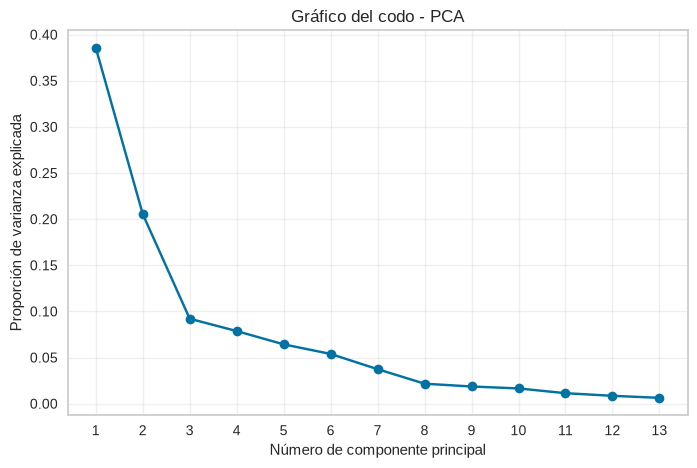

In [113]:
varianza = pca.explained_variance_ratio_

# Gráfico del codo
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(varianza) + 1),
    varianza,
    marker="o"
)

plt.xlabel("Número de componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("Gráfico del codo - PCA")
plt.xticks(range(1, len(varianza) + 1))
plt.grid(True, alpha=0.3)
plt.show()

Me quedaria con 3 componentes ya que es un punto de inflexion donde en adelante la varianza acumulada no tendra grandes incrementos.

<h3>Inciso b

- Que son los autovectores?: Representan la direccion de variabilidad de un componente asociandose a un autovalor. Consta de la combinacion lineal de cada elemento del autovector con la variable original X, como por ejemplo C1 = q11 . X1 + q21 . X2. El autovector tiene tanta dimension como cantidad de variables.

- Que son los autovalores?: Representan la varianza explicada de un componente en especifico donde la suma de todos los autovalores representa el 100% de la varianza de los datos

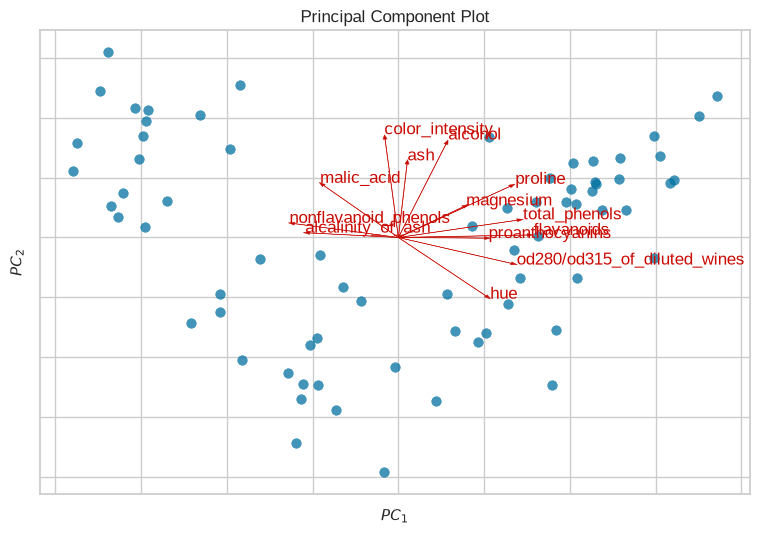

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [117]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
df_viz = df.drop(columns="target").select_dtypes(include="number")
viz.fit_transform(df_viz)
# y pedimos que se grafique
viz.show()

In [118]:
loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=df.drop(columns="target").select_dtypes(include="number").columns,
    columns=["PC1", "PC2"]
)

print(loadings.sort_values("PC1", ascending=False))

                                   PC1       PC2
flavanoids                    0.403831  0.013322
total_phenols                 0.372299  0.092784
od280/od315_of_diluted_wines  0.353583 -0.138852
proline                       0.349224  0.274495
hue                           0.274308 -0.313806
proanthocyanins               0.269532 -0.003226
magnesium                     0.202408  0.164182
alcohol                       0.149080  0.501673
ash                           0.027107  0.394652
color_intensity              -0.041801  0.528691
malic_acid                   -0.233847  0.279415
alcalinity_of_ash            -0.278070  0.024589
nonflavanoid_phenols         -0.325207  0.074353


Podemos ver que las variables que explican la mayor variabilidad de la componente 1 son target, nonflavanoid_phenols y alcanility_of_ash en la direccion positiva pero en la direccion negativa tenemos flavanoids, total_phenols, od280/od315_of_diluted_wines y proline

In [119]:
c1 = ""
for i, col in enumerate(loadings.index):
    if i < len(loadings.index)-1:
        c1 = c1 + "(" + str(loadings.loc[col, "PC1"]) + " * " + col + ") + "
    else:
        c1 = c1 + "(" + str(loadings.loc[col, "PC1"]) + " * " + col + ")"

print("C1 = " + c1)

C1 = (0.1490799309453308 * alcohol) + (-0.2338465716612787 * malic_acid) + (0.027106801091971777 * ash) + (-0.27807040832548363 * alcalinity_of_ash) + (0.20240790949751647 * magnesium) + (0.3722992338575252 * total_phenols) + (0.40383119166505715 * flavanoids) + (-0.3252066054366561 * nonflavanoid_phenols) + (0.26953216951398185 * proanthocyanins) + (-0.0418013017571979 * color_intensity) + (0.2743075553466589 * hue) + (0.35358342938404136 * od280/od315_of_diluted_wines) + (0.3492242257258251 * proline)


<h3>Inciso c

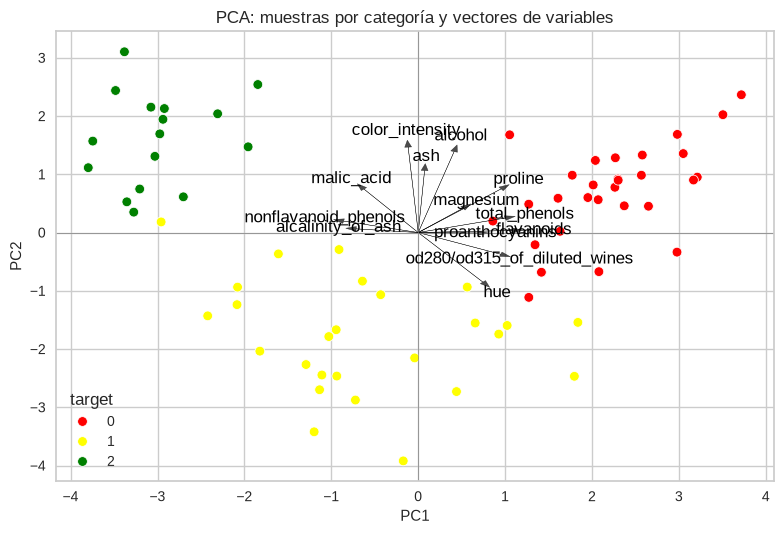

In [121]:
y = df["target"]
# DataFrame con las coordenadas de las muestras
df_pca = pd.DataFrame({
    "PC1": principalComponents[:, 0],
    "PC2": principalComponents[:, 1],
    "target": y.values
})

# Graficar muestras
ax = sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="target",
    palette=["red", "yellow", "green"]
)

# Agregar vectores de las variables
escala = 3  # Ajustá este valor si las flechas quedan muy chicas o grandes

for i, variable in enumerate(X.columns):
    x_vector = pca.components_[0, i] * escala
    y_vector = pca.components_[1, i] * escala

    ax.arrow(
        0, 0,
        x_vector, y_vector,
        color="black",
        alpha=0.7,
        head_width=0.08,
        length_includes_head=True
    )

    ax.text(
        x_vector * 1.1,
        y_vector * 1.1,
        variable,
        color="black",
        ha="center",
        va="center"
    )

plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)
plt.title("PCA: muestras por categoría y vectores de variables")
plt.tight_layout()
plt.show()

Podemos observar 3 grupos diferentes segun la variable target donde comparando el target 2 con el target 0 podemos observar como el primero se encuentra evidenciado por las direcciones de variables como malic_acid, nonflavanoid_phenols, alcalinity_of_ash. Por otro lado, se encuentra evidenciado por aproximadamente direcciones opuestas dadas por variables como proline, magnesium, total_phenols, hue, etc. En resumen, podemos observar como el grupo con target 2 representa direcciones negativas al incremento del componente 1 mientras que el grupo con target 0, aporta al incremento del mismo, representando esto que son dos tipos de vino totalmente diferentes entre si.